# Yak: RLCD (Brier reward) and the Week 5 benchmark

This notebook starts from the **finished supervised checkpoint** (`best.pt` from `Yak_Finetune_Mixture.ipynb`). It does no
further supervised training. It does two things:

1. **RLCD (Week 4).** Fine-tune the checkpoint with the Brier score as the objective, so the probabilities can be trusted.
   Compared with the supervised model and with the supervised model plus temperature scaling.
2. **Benchmark (Week 5).** Score both models on data they have never seen, with label names they never saw, to check
   generalisation: AG News, Emotion and SST-2.

```
 best.pt (supervised)  ----------------------------------------------+
        |                                                              |
        v                                                              v
 [RLCD] same mixture sampler, loss = Brier of the slot softmax     [baseline: SFT, SFT + temperature]
        |   low learning rate, accuracy guard, keep the best epoch      |
        v                                                              |
 rlcd_best.pt  --------------- same test sets, 4 label orders ---------+--> Week 4 table + reliability plots
        |
        v
 [benchmark]  unseen datasets, candidate labels = the dataset's class names
        |     (SFT vs RLCD, label-wording variants, chance, TF-IDF reference)
        v
 Week 5 table + plots
```

**Why direct Brier works as the "reward".** `loss = sum_k (p_k - y_k)^2` is the negative of the reward in the README. It is smooth in
the model's scores, so the gradient can be taken exactly and no sampling is needed. Brier is a strictly proper scoring rule,
so the best the model can do is report what it truly believes.

Run this from anywhere inside the repository. `Data/processed/train.jsonl` is needed (RLCD trains on the same rows as the
supervised run); validation picks the epoch and the test splits are only used at the end.

In [1]:
import os, sys, json, random, time, types, subprocess, copy

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:                                   # Google Colab: mount Drive and get the repository
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/Yak"):
        subprocess.run(["git", "clone", "--branch", "feature/finetune",
                        "https://github.com/gowthambalachandhiran/Yak.git", "/content/Yak"], check=True)
    os.chdir("/content/Yak")

def find_root(start="."):
    p = os.path.abspath(start)
    while True:
        if os.path.isdir(os.path.join(p, "Model")) and os.path.isdir(os.path.join(p, "Tokenizer")):
            return p
        if os.path.dirname(p) == p:
            raise RuntimeError("run this notebook inside the Yak repository (Model/ and Tokenizer/ not found)")
        p = os.path.dirname(p)

ROOT = find_root()
os.chdir(ROOT); sys.path.insert(0, ROOT)
FT_DIR = None                                  # the folder with Utils/ (spelled FineTuning in git, Finetuning on some disks)
for cand in ("FineTuning", "Finetuning"):
    if os.path.isdir(os.path.join(ROOT, "Model", "OurExperiments", cand, "Utils")):
        FT_DIR = os.path.join(ROOT, "Model", "OurExperiments", cand)
        break
assert FT_DIR, "Model/OurExperiments/FineTuning/Utils not found"
sys.path.insert(0, FT_DIR)
print("repository root:", ROOT)
print("helper modules :", os.path.join(FT_DIR, "Utils"))

repository root: c:\Users\DELL\Downloads\Project Yak\Yak
helper modules : c:\Users\DELL\Downloads\Project Yak\Yak\Model\OurExperiments\FineTuning\Utils


In [2]:
# ---------------- configuration (edit these) ----------------
# The supervised checkpoint to start from. The first existing path in this list is used.
CKPT_CANDIDATES = [
    os.environ.get("YAK_CKPT", ""),                       # or: export YAK_CKPT=/path/to/best.pt
    "/content/drive/MyDrive/Yak/finetune_mixture/best.pt",
    "runs/mixture/best.pt",
    "best.pt",
]
OUT_DIR = "/content/drive/MyDrive/Yak/rlcd" if IN_COLAB else "runs/rlcd"      # rlcd_seed*.pt and results go here
PROCESSED_DIR = "Data/processed"                          # train/validation/test.jsonl (train.jsonl is needed for RLCD)

TASKS = ["banking77", "clinc", "snli"]                    # must match the checkpoint
OOS_BOOST = 5                                             # same as the supervised run
MIX = "equal"
BATCH_SIZES = {"banking77": 32, "clinc": 16, "snli": 64}

# ---- RLCD ----
LOSS = "brier"                                            # the objective. "brier" is the RLCD reward; "ce" is only for comparison
CE_WEIGHT = 0.0                                           # optional extra cross-entropy term (0 = pure Brier)
RLCD_EPOCHS, STEPS_PER_EPOCH = 3, 500
LR, HEAD_LR, WEIGHT_DECAY, WARMUP_FRAC = 2e-5, 1e-4, 0.01, 0.1   # low, because we only want to adjust calibration
FULL_PROB, MIN_LABELS = 0.7, 2                            # show all labels more often: that is how the model is tested
ACC_TOL = 0.01                                            # an epoch counts only if mean seen-class val accuracy drops by less than this
SEEDS = [0]                                               # README asks for 3 seeds: use [0, 1, 2] for the final run
EPOCH_EVAL_LIMIT = 1000                                   # validation rows per task in the per-epoch check

# ---- evaluation ----
TTA = 4                                                   # label orders averaged at test time
EVAL_BATCH = 64
D_MODEL, NHEAD, LAYERS, MAX_SEQ, DROPOUT = 128, 4, 4, 2048, 0.1   # must match the checkpoint

# ---- Week 5 benchmark ----
BENCH = ["ag_news", "emotion", "sst2"]                    # unseen datasets (downloaded with the `datasets` library)
BENCH_LIMIT = 2000                                        # test rows per dataset
BENCH_FIT = 1000                                          # benchmark train rows, used ONLY for the diagnostic temperature and the TF-IDF reference
SEED = 0

CKPT = next((p for p in CKPT_CANDIDATES if p and os.path.exists(p)), None)
if CKPT is None:
    raise FileNotFoundError("best.pt not found. Tried:\n  " + "\n  ".join(p or "(YAK_CKPT not set)" for p in CKPT_CANDIDATES)
                            + "\nSet YAK_CKPT or add your path to CKPT_CANDIDATES.")
os.makedirs(OUT_DIR, exist_ok=True)
print("checkpoint:", CKPT)

checkpoint: runs/mixture/best.pt


## What the reward looks like
The Brier score of one example is `sum_k (p_k - y_k)^2`. 0 is perfect, 2 is the worst. Unlike accuracy, it punishes a wrong
answer more when the model was sure, and also punishes an unsure right answer a little. That is what pushes confidence
towards the real hit rate.

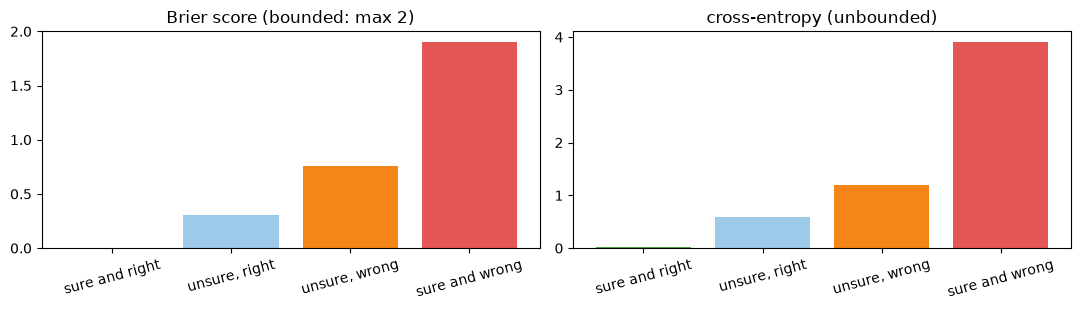

sure and right  p=[0.97, 0.02, 0.01]  Brier 0.001  CE 0.030
unsure, right   p=[0.55, 0.25, 0.2]  Brier 0.305  CE 0.598
unsure, wrong   p=[0.3, 0.45, 0.25]  Brier 0.755  CE 1.204
sure and wrong  p=[0.02, 0.97, 0.01]  Brier 1.901  CE 3.912


In [3]:
import numpy as np
import matplotlib.pyplot as plt

cases = {
    "sure and right": [0.97, 0.02, 0.01],
    "unsure, right": [0.55, 0.25, 0.20],
    "unsure, wrong": [0.30, 0.45, 0.25],
    "sure and wrong": [0.02, 0.97, 0.01],
}
y = np.array([1.0, 0.0, 0.0])                      # the true class is class 0
brier_vals = {k: float(((np.array(p) - y) ** 2).sum()) for k, p in cases.items()}
ce_vals = {k: float(-np.log(p[0])) for k, p in cases.items()}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(list(brier_vals), list(brier_vals.values()), color=["#54A24B", "#9ecae9", "#F58518", "#E45756"])
ax[0].set_title("Brier score (bounded: max 2)"); ax[0].set_ylim(0, 2)
ax[1].bar(list(ce_vals), list(ce_vals.values()), color=["#54A24B", "#9ecae9", "#F58518", "#E45756"])
ax[1].set_title("cross-entropy (unbounded)")
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
for k in cases:
    print(f"{k:15s} p={cases[k]}  Brier {brier_vals[k]:.3f}  CE {ce_vals[k]:.3f}")

## Packing, data and model
The packing cell, the classifier and the evaluation helpers are the same code as in `Yak_Finetune_Mixture.ipynb`, so the
checkpoint loads without any change. Held-out classes are read from the checkpoint, so RLCD never trains on a class the
supervised run held out.

In [4]:
# cell: packing
import random
from Utils.FastBpe import normalize_text, normalize_label


LABEL_ALIASES = {"oos": "out of scope"}   # names that carry no meaning as words


class Packer:
    def __init__(self, fast_bpe, class_names, max_labels=160, max_text_tokens=96,
                 max_label_tokens=12, aliases=None, max_premise_tokens=64, max_hypothesis_tokens=32):
        """
        fast_bpe:        FastBPE
        class_names:     list of class names, the position is the class id
        max_labels:      upper bound M on labels in one packed example
        max_text_tokens: the text is cut to this many tokens
        max_label_tokens: each label is cut to this many tokens
        """
        self.bpe = fast_bpe
        self.class_names = list(class_names)
        self.num_classes = len(self.class_names)
        self.max_labels = min(max_labels, self.num_classes)
        self.train_ids = list(range(self.num_classes))     # classes that may appear as training candidates
        self.max_text_tokens = max_text_tokens
        self.max_premise_tokens = max_premise_tokens
        self.max_hypothesis_tokens = max_hypothesis_tokens
        aliases = LABEL_ALIASES if aliases is None else aliases
        self.label_ids = []
        for name in self.class_names:
            ids = fast_bpe.encode_ids(normalize_label(aliases.get(name, name)), normalize=True)
            ids = ids[:max_label_tokens] or [fast_bpe.unk_id]
            self.label_ids.append(ids)

    # ------------------------------------------------------------------ text
    def encode_text(self, text):
        return self.bpe.encode_ids(text, normalize=True)[: self.max_text_tokens]

    def encode_pair(self, premise, hypothesis):
        """Sentence pair as one 'text': premise tokens [SEP] hypothesis tokens, each cut separately.
        The model has no segment embeddings, so the [SEP] between them is the only divider."""
        p = self.bpe.encode_ids(premise, normalize=True)[: self.max_premise_tokens]
        h = self.bpe.encode_ids(hypothesis, normalize=True)[: self.max_hypothesis_tokens]
        return p + [self.bpe.sep_id] + h

    def encode_row(self, row):
        if "premise" in row:
            return self.encode_pair(row["premise"], row["hypothesis"])
        return self.encode_text(row["text"])

    def max_text_len(self):
        return max(self.max_text_tokens, self.max_premise_tokens + 1 + self.max_hypothesis_tokens)

    # ------------------------------------------------------------------ packing
    def pack(self, text_ids, class_order):
        """Return (ids, label_pos) for the given text ids and classes in the given order."""
        ids = [self.bpe.cls_id] + list(text_ids) + [self.bpe.sep_id]
        label_pos = []
        for c in class_order:
            label_pos.append(len(ids))
            ids.extend(self.label_ids[c])
            ids.append(self.bpe.sep_id)
        return ids, label_pos

    def max_packed_len(self):
        longest = sorted((len(x) + 1 for x in self.label_ids), reverse=True)[: self.max_labels]
        return 2 + self.max_text_len() + sum(longest)

    def set_train_classes(self, class_ids):
        """Restrict training candidates to class_ids (the rest are held out and never shown in training).
        Evaluation still uses every class."""
        self.train_ids = sorted(class_ids)

    # ------------------------------------------------------------------ choosing the label list
    def train_labels(self, true_class, rng, full_prob=0.5, min_labels=2):
        """Random label list that always contains true_class.

        With probability full_prob use as many labels as allowed (so the model sees the real test
        condition), otherwise draw the count uniformly from min_labels..max_labels.
        """
        assert true_class in self.train_ids, f"class {true_class} is held out and cannot be a training target"
        cap = min(self.max_labels, len(self.train_ids))
        lo = min(min_labels, cap)
        n = cap if rng.random() < full_prob else rng.randint(lo, cap)
        others = [c for c in self.train_ids if c != true_class]
        chosen = rng.sample(others, n - 1) + [true_class]
        rng.shuffle(chosen)
        return chosen

    def eval_labels(self, true_class, rng=None):
        """All classes (up to max_labels). If there are more classes than max_labels, keep the true
        label plus a fixed-seed random subset. Order is class-id order unless rng shuffles it."""
        order = list(range(self.num_classes))
        if self.num_classes > self.max_labels:
            sub_rng = random.Random(true_class)
            others = [c for c in order if c != true_class]
            order = sorted(sub_rng.sample(others, self.max_labels - 1) + [true_class])
        if rng is not None:
            rng.shuffle(order)
        return order


class ClsDataset:
    """Map-style dataset (works with torch DataLoader, no torch import needed here).

    rows:   list of dicts with "text" and "label" (the jsonl format written by Data/*.py)
    train:  True  -> random label subsets and order, different every epoch (call set_epoch)
            False -> all labels in class order
    """

    def __init__(self, rows, packer, train, seed=0, full_prob=0.5, min_labels=2, eval_shuffle_seed=None, task_id=0):
        self.packer = packer
        self.task_id = task_id
        self.train = train
        self.seed = seed
        self.epoch = 0
        self.full_prob = full_prob
        self.min_labels = min_labels
        self.eval_shuffle_seed = eval_shuffle_seed   # None = class-id order; int = a fixed shuffled order
        self.text_ids = [packer.encode_row(r) for r in rows]      # single texts or premise/hypothesis pairs
        self.labels = [int(r["label"]) for r in rows]

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.example(idx, self.epoch * 10_007 + idx)

    def example(self, idx, nonce):
        """Example idx with a label list drawn from `nonce` (a different nonce gives a different list)."""
        true_class = self.labels[idx]
        if self.train:
            rng = random.Random(self.seed * 1_000_003 + nonce)
            order = self.packer.train_labels(true_class, rng, self.full_prob, self.min_labels)
        else:
            rng = None
            if self.eval_shuffle_seed is not None:
                rng = random.Random(self.eval_shuffle_seed * 1_000_003 + idx)
            order = self.packer.eval_labels(true_class, rng)
        ids, label_pos = self.packer.pack(self.text_ids[idx], order)
        return {"ids": ids, "label_pos": label_pos, "slot_class": order,
                "target": order.index(true_class), "true_class": true_class, "task_id": self.task_id}


def collate_lists(batch, pad_id):
    """Pad a list of examples to the longest sequence and the largest label count in the batch.

    Returns plain python lists so it can be tested without torch:
        ids [B, L] (pad_id), label_pos [B, M] (0 for unused), label_mask [B, M] (True = real label),
        slot_class [B, M] (-1 for unused), target [B], true_class [B]
    """
    L = max(len(b["ids"]) for b in batch)
    M = max(len(b["label_pos"]) for b in batch)
    out = {"ids": [], "label_pos": [], "label_mask": [], "slot_class": [], "target": [], "true_class": [],
           "task_id": []}
    for b in batch:
        n = len(b["label_pos"])
        out["ids"].append(b["ids"] + [pad_id] * (L - len(b["ids"])))
        out["label_pos"].append(b["label_pos"] + [0] * (M - n))
        out["label_mask"].append([True] * n + [False] * (M - n))
        out["slot_class"].append(b["slot_class"] + [-1] * (M - n))
        out["target"].append(b["target"])
        out["true_class"].append(b["true_class"])
        out["task_id"].append(b.get("task_id", 0))
    return out


def make_collate(pad_id):
    """Collate function for torch DataLoader: python lists -> tensors."""
    def collate(batch):
        import torch
        d = collate_lists(batch, pad_id)
        return {
            "ids": torch.tensor(d["ids"], dtype=torch.long),
            "label_pos": torch.tensor(d["label_pos"], dtype=torch.long),
            "label_mask": torch.tensor(d["label_mask"], dtype=torch.bool),
            "slot_class": torch.tensor(d["slot_class"], dtype=torch.long),
            "target": torch.tensor(d["target"], dtype=torch.long),
            "true_class": torch.tensor(d["true_class"], dtype=torch.long),
            "task_id": torch.tensor(d["task_id"], dtype=torch.long),
        }
    return collate


In [5]:
import torch
from Tokenizer.Tokenizer import BPE
from Utils.FastBpe import FastBPE
from Utils.Mixture import (load_processed, apply_holdout, split_seen_unseen, mixture_weights,
                           MixtureBatchSampler, MixedTrainDataset)

ck = torch.load(CKPT, map_location="cpu", weights_only=False)      # your own file
assert isinstance(ck, dict) and "model" in ck, "expected a checkpoint saved by Yak_Finetune_Mixture.ipynb (keys: model, tasks, held_out)"
print("checkpoint epoch:", ck.get("epoch"), "| tasks:", ck.get("tasks"))
assert set(TASKS) <= set(ck.get("tasks", TASKS)), "TASKS does not match the checkpoint"

bpe = BPE(); bpe.load("Tokenizer/TokenFile/bpe.json")
fb = FastBPE(bpe)
rng = random.Random(SEED)

loaded = load_processed(PROCESSED_DIR, fb, Packer, datasets=TASKS, max_labels=160)
tasks = []
for t in loaded:
    name = t["name"]
    if OOS_BOOST > 1 and t["oos_index"] is not None:
        oos_rows = [r for r in t["train"] if r["label"] == t["oos_index"]]
        t["train"] = t["train"] + oos_rows * (OOS_BOOST - 1)
    held = [int(c) for c in ck.get("held_out", {}).get(name, [])]
    apply_holdout(t, held)                                              # exactly the classes the supervised run held out
    for split in ("val", "test"):
        seen, unseen = split_seen_unseen(t[split], t["held_out"])
        rng.shuffle(seen); rng.shuffle(unseen)
        t[split + "_seen"], t[split + "_unseen"] = seen, unseen
    tasks.append(t)

print(f"{'task':11s}{'classes':>8s}{'held out':>9s}{'train':>9s}{'val':>7s}{'test':>7s}{'chance':>8s}")
for t in tasks:
    print(f"{t['name']:11s}{len(t['names']):8d}{len(t['held_out']):9d}{len(t['train']):9d}{len(t['val']):7d}"
          f"{len(t['test']):7d}{1 / len(t['names']):8.3f}")

c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


checkpoint epoch: 5 | tasks: ['banking77', 'clinc', 'snli']
task        classes held out    train    val   test  chance
banking77        77       15     7186   1000   3080   0.013
clinc           151       30     7432   3100   5500   0.007
snli              3        0     9003   9842   9824   0.333


In [6]:
# cell: classifier
import torch
import torch.nn as nn
import torch.nn.functional as F

from Model.LayerOne.EmbedPostional import EmbedPos
from Model.EncoderBlock import EncoderBlock


class YakClassifier(nn.Module):
    """Label-scoring classifier on top of the pre-trained Yak encoder.

    packed ids -> EmbedPos -> N x EncoderBlock -> final LayerNorm -> h [B, L, d]
    gather h at the first token of every label  -> H [B, M, d]
    shared scorer Linear(d, 1)                  -> scores [B, M]
    padded slots set to -inf                    -> softmax over slots happens in the loss / at inference

    The layer names (embed, blocks, final_norm) match MlmModel, so the phase 1 checkpoint loads directly.
    The MLM head and its bias are not part of this model.
    """

    def __init__(self, vocab_size: int, d_model: int, nhead: int, num_layers: int,
                 max_seq_len: int, dropout: float = 0.1, pad_token_id: int = 0):
        super().__init__()
        self.pad_id = pad_token_id
        self.embed = EmbedPos(vocab_size, d_model=d_model, max_len=max_seq_len,
                              pad_id=pad_token_id, dropout=dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, nhead, dropout) for _ in range(num_layers)])
        self.final_norm = nn.LayerNorm(d_model)
        self.scorer = nn.Linear(d_model, 1)           # the only new weights: d_model + 1
        nn.init.normal_(self.scorer.weight, mean=0.0, std=0.02)
        nn.init.zeros_(self.scorer.bias)

    # ------------------------------------------------------------------ weights
    def load_pretrained(self, path: str, map_location="cpu"):
        """Load embedding, blocks and final norm from a phase 1 checkpoint. Returns a short report."""
        try:
            sd = torch.load(path, map_location=map_location, weights_only=True)
        except Exception:                                   # checkpoint holds more than plain tensors
            sd = torch.load(path, map_location=map_location, weights_only=False)   # only for your own files
        meta = {k: v for k, v in sd.items() if isinstance(v, (int, float, str))} if isinstance(sd, dict) else {}
        if isinstance(sd, dict):
            for key in ("model", "model_state", "model_state_dict", "state_dict"):
                if key in sd and isinstance(sd[key], dict):
                    sd = sd[key]
                    break
        clean = {}
        for k, v in sd.items():
            for prefix in ("module.", "_orig_mod."):
                if k.startswith(prefix):
                    k = k[len(prefix):]
            if k.startswith(("embed.", "blocks.", "final_norm.")):
                clean[k] = v
        missing, unexpected = self.load_state_dict(clean, strict=False)
        missing = [k for k in missing if not k.startswith("scorer.")]   # scorer is new, expected missing
        if missing or unexpected or not clean:
            raise RuntimeError(f"checkpoint does not match: missing={missing[:5]} unexpected={unexpected[:5]} "
                               f"loaded={len(clean)}")
        return {"loaded_tensors": len(clean), "head_keys_ignored": [k for k in sd if k.startswith("head")],
                "checkpoint_info": meta}

    def num_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters())

    def set_encoder_trainable(self, trainable: bool):
        """Freeze or unfreeze embedding and blocks. The final norm and scorer always train."""
        for p in self.embed.parameters():
            p.requires_grad = trainable
        for p in self.blocks.parameters():
            p.requires_grad = trainable

    # ------------------------------------------------------------------ forward
    def encode(self, ids: torch.Tensor) -> torch.Tensor:
        keep = ids != self.pad_id
        padding_mask = None if bool(keep.all()) else keep
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, padding_mask)
        return self.final_norm(x)

    def score(self, ids: torch.Tensor, label_pos: torch.Tensor, label_mask: torch.Tensor) -> torch.Tensor:
        """ids [B, L], label_pos [B, M] (0 for unused slots), label_mask [B, M] True for real labels.
        Returns scores [B, M] with -inf in unused slots."""
        h = self.encode(ids)                                                   # [B, L, d]
        idx = label_pos.unsqueeze(-1).expand(-1, -1, h.size(-1))               # [B, M, d]
        H = torch.gather(h, 1, idx)                                            # [B, M, d]
        scores = self.scorer(H).squeeze(-1)                                    # [B, M]
        return scores.masked_fill(~label_mask, float("-inf"))

    def forward(self, ids, label_pos, label_mask, target=None, loss_type: str = "ce"):
        """target is the slot index of the true label, shape [B]. Returns scores, or (loss, scores)."""
        scores = self.score(ids, label_pos, label_mask)
        if target is None:
            return scores
        return self.loss(scores, target, loss_type), scores

    @staticmethod
    def loss(scores: torch.Tensor, target: torch.Tensor, loss_type: str = "ce") -> torch.Tensor:
        scores = scores.float()
        if loss_type == "ce":
            return F.cross_entropy(scores, target)
        if loss_type == "brier":
            p = F.softmax(scores, dim=-1)                                      # -inf slots become exactly 0
            y = F.one_hot(target, p.size(-1)).to(p.dtype)
            return ((p - y) ** 2).sum(dim=-1).mean()
        raise ValueError(f"unknown loss {loss_type}")


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

def new_model():
    return YakClassifier(fb.vocab_size, D_MODEL, NHEAD, LAYERS, MAX_SEQ, DROPOUT, fb.pad_id).to(device)

sft_state = {k: v.detach().cpu().clone() for k, v in ck["model"].items()}
model = new_model()
model.load_state_dict(sft_state)                  # strict: every tensor must match
print(f"device {device} | parameters {model.num_parameters():,} | loaded the supervised checkpoint")

device cpu | parameters 4,634,113 | loaded the supervised checkpoint


In [8]:
# cell: eval_helpers
import contextlib
import numpy as np
import torch
from torch.utils.data import DataLoader
from Utils.Metrics import softmax, slots_to_class_probs

def amp_setup(device, use_amp):
    if use_amp and device.type == "cuda":
        # bf16 needs an Ampere (compute capability 8+) GPU; a T4 is 7.5 and should use fp16 (plus loss scaling)
        dtype = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
        return (lambda: torch.autocast("cuda", dtype=dtype)), dtype
    return (lambda: contextlib.nullcontext()), None


@torch.no_grad()
def predict(model, dataset, device, batch_size, collate, autocast):
    """Return slot scores [N, M], slot classes [N, M] (-1 = unused), target slots [N], true classes [N]."""
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate)
    S, C, T, Y = [], [], [], []
    for b in loader:
        with autocast():
            scores = model(b["ids"].to(device), b["label_pos"].to(device), b["label_mask"].to(device))
        S.append(scores.float().cpu().numpy())
        C.append(b["slot_class"].numpy())
        T.append(b["target"].numpy())
        Y.append(b["true_class"].numpy())
    M = max(s.shape[1] for s in S)
    S = np.concatenate([np.pad(s, ((0, 0), (0, M - s.shape[1])), constant_values=-np.inf) for s in S])
    C = np.concatenate([np.pad(c, ((0, 0), (0, M - c.shape[1])), constant_values=-1) for c in C])
    return S, C, np.concatenate(T), np.concatenate(Y)


def eval_probs(model, rows, packer, args, device, collate, autocast, n_orders=1, temperature=1.0):
    """Class probabilities [N, K] averaged over n_orders label orders (the first is class-id order)."""
    acc, true, first = None, None, None
    for k in range(n_orders):
        ds = ClsDataset(rows, packer, train=False, eval_shuffle_seed=None if k == 0 else k)
        S, C, T, Y = predict(model, ds, device, args.eval_batch_size, collate, autocast)
        if k == 0:
            first = (S, T)
        P = slots_to_class_probs(softmax(S, temperature), C, packer.num_classes)
        acc = P if acc is None else acc + P
        true = Y
    return acc / n_orders, true, first


In [9]:
from torch.utils.data import DataLoader
from Utils.Metrics import report, fit_temperature, oos_report, softmax, slots_to_class_probs

ev_args = types.SimpleNamespace(eval_batch_size=EVAL_BATCH)
autocast, amp_dtype = amp_setup(device, True)
collate = make_collate(fb.pad_id)

def task_eval(m, t, split, n_orders=1, temp=1.0, limit=None):
    rows = t[split]
    rows = rows if limit is None else rows[:limit]
    if not rows:
        return None
    P, Y, first = eval_probs(m, rows, t["packer"], ev_args, device, collate, autocast, n_orders, temp)
    return report(P, Y), P, Y, first

def macro_f1(P, Y, K):
    pred, f = P.argmax(1), []
    for c in range(K):
        tp = int(((pred == c) & (Y == c)).sum()); fp = int(((pred == c) & (Y != c)).sum()); fn = int(((pred != c) & (Y == c)).sum())
        if tp + fp + fn:
            f.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f)) if f else 0.0

def rel_curve(P, Y, bins=10, min_n=20):
    conf, hit = P.max(1), (P.argmax(1) == Y)
    edges, xs, ys = np.linspace(0, 1, bins + 1), [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= min_n:
            xs.append(float(conf[m].mean())); ys.append(float(hit[m].mean()))
    return xs, ys

def full_eval(m):
    """Test metrics for one model: seen and held-out classes, T=1 and the temperature fitted on seen-class validation."""
    out, store, temps = {}, {}, {}
    for t in tasks:
        name = t["name"]
        _, _, _, first = task_eval(m, t, "val_seen")
        temps[name] = fit_temperature(first[0], first[1])
        for kind in ("test_seen", "test_unseen"):
            for setting, temp in (("T=1", 1.0), ("T fitted", temps[name])):
                r = task_eval(m, t, kind, TTA, temp)
                if r is None:
                    continue
                met, P, Y, _ = r
                met = dict(met); met["f1"] = macro_f1(P, Y, len(t["names"]))
                if t["oos_index"] is not None and kind == "test_seen":
                    met["oos"] = oos_report(P, Y, t["oos_index"])
                out[(name, kind, setting)] = met
                store[(name, kind, setting)] = (P, Y)
    return out, store, temps

def mean_std(outs, key, metric):
    v = [o[key][metric] for o in outs if key in o]
    return (float(np.mean(v)), float(np.std(v)) if len(v) > 1 else 0.0) if v else (None, None)

def show_compare(sft_out, rlcd_outs):
    cols = ("acc", "f1", "brier", "nll", "ece")
    for t in tasks:
        for kind in ("test_seen", "test_unseen"):
            if (t["name"], kind, "T=1") not in sft_out:
                continue
            n_rows = len(t[kind])
            print(f"\n{t['name']}  {kind[5:]} classes  (n={n_rows}, chance {1 / len(t['names']):.3f}, {TTA} label orders)")
            print(f"  {'model':12s}" + "".join(f"{c:>16s}" for c in cols))
            for label, setting, outs in (("SFT", "T=1", [sft_out]), ("SFT + T", "T fitted", [sft_out]),
                                         ("RLCD", "T=1", rlcd_outs), ("RLCD + T", "T fitted", rlcd_outs)):
                cells_ = []
                for c in cols:
                    m, s = mean_std(outs, (t["name"], kind, setting), c)
                    cells_.append(f"{m:.3f}" + (f" +-{s:.3f}" if len(outs) > 1 else "") if m is not None else "n/a")
                print(f"  {label:12s}" + "".join(f"{c_:>16s}" for c_ in cells_))

## Step 1: the supervised baseline
Evaluate `best.pt` as it is, and with a temperature fitted on seen-class validation data. This is the number RLCD has to beat.

In [10]:
sft_out, sft_store, sft_T = full_eval(model)
print("fitted temperatures (SFT):", {k: round(v, 2) for k, v in sft_T.items()})
show_compare(sft_out, [sft_out])

fitted temperatures (SFT): {'banking77': 0.91, 'clinc': 1.02, 'snli': 2.95}

banking77  seen classes  (n=2480, chance 0.013, 4 label orders)
  model                    acc              f1           brier             nll             ece
  SFT                    0.495           0.395           0.626           1.649           0.084
  SFT + T                0.495           0.396           0.620           1.634           0.064
  RLCD                   0.495           0.395           0.626           1.649           0.084
  RLCD + T               0.495           0.396           0.620           1.634           0.064

banking77  unseen classes  (n=600, chance 0.013, 4 label orders)
  model                    acc              f1           brier             nll             ece
  SFT                    0.185           0.062           0.950           3.611           0.115
  SFT + T                0.183           0.062           0.961           3.741           0.141
  RLCD                   0.185   

## Step 2: RLCD with the Brier objective
Each seed starts from the supervised weights and trains **all weights** at a low learning rate with `loss = Brier`.
After every epoch the model is scored on seen-class validation data. An epoch is only eligible if mean accuracy has dropped by less
than `ACC_TOL` compared with the supervised model. Among eligible epochs the one with the lowest mean validation Brier is kept. If
no epoch qualifies, the supervised weights are kept, and the report will say so.

In [11]:
import torch.nn.functional as F

def val_snapshot(m):
    snap = {}
    for t in tasks:
        r = task_eval(m, t, "val_seen", 1, 1.0, EPOCH_EVAL_LIMIT)
        snap[t["name"]] = r[0]
    return snap

def run_rlcd(seed):
    torch.manual_seed(seed); random.seed(seed)
    m = new_model(); m.load_state_dict(sft_state)
    mixed = MixedTrainDataset(tasks, ClsDataset, seed=seed, full_prob=FULL_PROB, min_labels=MIN_LABELS)
    sizes = mixed.sizes()
    sampler = MixtureBatchSampler(sizes, mixture_weights(sizes, MIX), [BATCH_SIZES[t["name"]] for t in tasks],
                                  STEPS_PER_EPOCH, seed=seed)
    loader = DataLoader(mixed, batch_sampler=sampler, collate_fn=collate, num_workers=0)
    head = list(m.scorer.parameters()) + list(m.final_norm.parameters())
    head_ids = {id(p) for p in head}
    dec, nodec = [], []
    for n, p in m.named_parameters():
        if id(p) not in head_ids:
            (nodec if (p.ndim < 2 or "embed" in n) else dec).append(p)
    opt = torch.optim.AdamW([{"params": dec, "lr": LR, "weight_decay": WEIGHT_DECAY},
                             {"params": nodec, "lr": LR, "weight_decay": 0.0},
                             {"params": head, "lr": HEAD_LR, "weight_decay": 0.0}])
    total = RLCD_EPOCHS * STEPS_PER_EPOCH
    warm = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    scaler = torch.cuda.amp.GradScaler(enabled=(amp_dtype == torch.float16))

    base = val_snapshot(m)
    base_acc = float(np.mean([v["acc"] for v in base.values()]))
    best_score = float(np.mean([v["brier"] for v in base.values()]))
    best_state, best_ep = {k: v.clone() for k, v in sft_state.items()}, -1
    history = [{"epoch": -1, "snap": base, "acc": base_acc, "brier": best_score, "eligible": True}]
    curve, running = [], None
    for ep in range(RLCD_EPOCHS):
        sampler.set_epoch(ep); m.train(); t0 = time.time()
        for i, b in enumerate(loader):
            b = {k: v.to(device) for k, v in b.items()}
            with autocast():
                loss, scores = m(b["ids"], b["label_pos"], b["label_mask"], b["target"], LOSS)
                if CE_WEIGHT:
                    loss = loss + CE_WEIGHT * F.cross_entropy(scores.float(), b["target"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            running = loss.item() if running is None else 0.95 * running + 0.05 * loss.item()
            curve.append(running)
            if (i + 1) % 250 == 0:
                print(f"  seed {seed} epoch {ep} step {i + 1}/{STEPS_PER_EPOCH} loss {running:.4f}")
        snap = val_snapshot(m)
        acc = float(np.mean([v["acc"] for v in snap.values()])); br = float(np.mean([v["brier"] for v in snap.values()]))
        ok = acc >= base_acc - ACC_TOL
        history.append({"epoch": ep, "snap": snap, "acc": acc, "brier": br, "eligible": ok})
        print(f"seed {seed} epoch {ep} ({time.time() - t0:.0f}s): val acc {acc:.4f} (SFT {base_acc:.4f}) | val Brier {br:.4f} "
              f"(best so far {best_score:.4f}) | " + ("eligible" if ok else "accuracy dropped too far, skipped"))
        if ok and br < best_score:
            best_score, best_ep = br, ep
            best_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    print(f"seed {seed}: kept " + ("the supervised weights (no epoch improved Brier within the accuracy tolerance)" if best_ep < 0 else f"epoch {best_ep}"))
    return m, history, curve, best_ep

runs = []
for sd in SEEDS:
    m, hist, curve, best_ep = run_rlcd(sd)
    runs.append({"seed": sd, "model": m, "history": hist, "curve": curve, "best_epoch": best_ep})
    torch.save({"model": m.state_dict(), "tasks": TASKS, "held_out": {t["name"]: t["held_out"] for t in tasks},
                "rlcd": {"seed": sd, "best_epoch": best_ep, "loss": LOSS, "lr": LR, "epochs": RLCD_EPOCHS}},
               os.path.join(OUT_DIR, f"rlcd_seed{sd}.pt"))
print("saved:", [f"rlcd_seed{r['seed']}.pt" for r in runs], "in", OUT_DIR)

C:\Users\DELL\AppData\Local\Temp\ipykernel_7572\365506165.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(amp_dtype == torch.float16))


  seed 0 epoch 0 step 250/500 loss 0.5610
  seed 0 epoch 0 step 500/500 loss 0.5393
seed 0 epoch 0 (2552s): val acc 0.5019 (SFT 0.4940) | val Brier 0.6377 (best so far 0.6409) | eligible
  seed 0 epoch 1 step 250/500 loss 0.5560
  seed 0 epoch 1 step 500/500 loss 0.5214
seed 0 epoch 1 (1546s): val acc 0.5015 (SFT 0.4940) | val Brier 0.6379 (best so far 0.6377) | eligible
  seed 0 epoch 2 step 250/500 loss 0.5330
  seed 0 epoch 2 step 500/500 loss 0.5617
seed 0 epoch 2 (1011s): val acc 0.5025 (SFT 0.4940) | val Brier 0.6365 (best so far 0.6377) | eligible
seed 0: kept epoch 2
saved: ['rlcd_seed0.pt'] in runs/rlcd


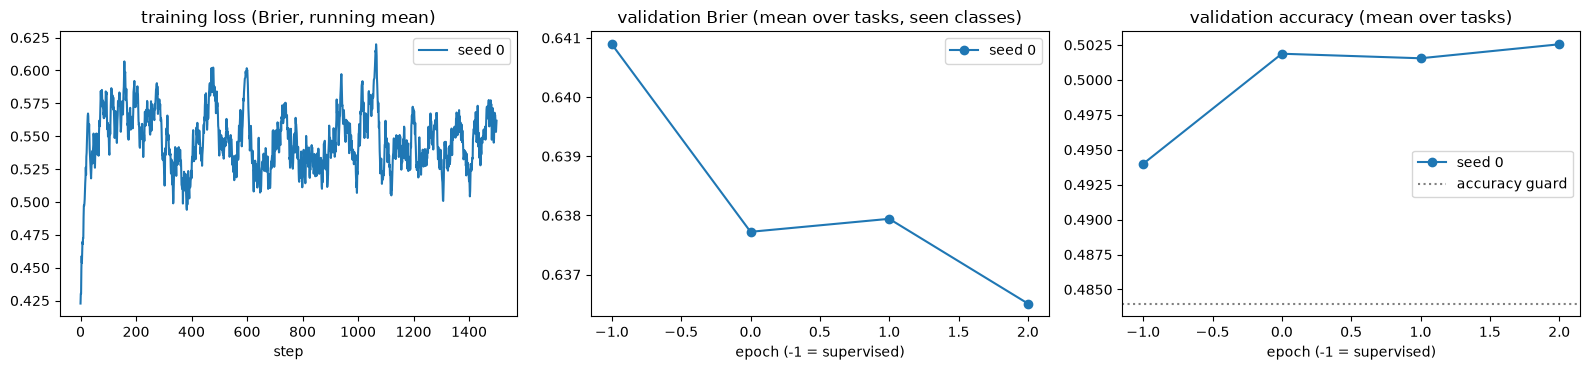

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for r in runs:
    ax[0].plot(r["curve"], label=f"seed {r['seed']}")
    xs = [h["epoch"] for h in r["history"]]
    ax[1].plot(xs, [h["brier"] for h in r["history"]], marker="o", label=f"seed {r['seed']}")
    ax[2].plot(xs, [h["acc"] for h in r["history"]], marker="o", label=f"seed {r['seed']}")
ax[0].set_title("training loss (Brier, running mean)"); ax[0].set_xlabel("step")
ax[1].set_title("validation Brier (mean over tasks, seen classes)"); ax[1].set_xlabel("epoch (-1 = supervised)")
ax[2].set_title("validation accuracy (mean over tasks)"); ax[2].set_xlabel("epoch (-1 = supervised)")
base_acc0 = runs[0]["history"][0]["acc"]
ax[2].axhline(base_acc0 - ACC_TOL, color="gray", ls=":", label="accuracy guard")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## Step 3: test results, supervised vs RLCD
Same test sets and the same 4 label orders. Rows: the supervised model, the supervised model with a fitted temperature (the cheap
baseline), RLCD, and RLCD with a fitted temperature (should end near T = 1 if RLCD did its job).

In [13]:
rlcd_results = []
for r in runs:
    o, s, T = full_eval(r["model"])
    rlcd_results.append({"seed": r["seed"], "out": o, "store": s, "T": T})
    print(f"seed {r['seed']} fitted temperatures after RLCD:", {k: round(v, 2) for k, v in T.items()})
rlcd_outs = [r["out"] for r in rlcd_results]
show_compare(sft_out, rlcd_outs)

seed 0 fitted temperatures after RLCD: {'banking77': 0.91, 'clinc': 1.02, 'snli': 3.13}

banking77  seen classes  (n=2480, chance 0.013, 4 label orders)
  model                    acc              f1           brier             nll             ece
  SFT                    0.495           0.395           0.626           1.649           0.084
  SFT + T                0.495           0.396           0.620           1.634           0.064
  RLCD                   0.506           0.403           0.616           1.629           0.083
  RLCD + T               0.505           0.402           0.611           1.615           0.062

banking77  unseen classes  (n=600, chance 0.013, 4 label orders)
  model                    acc              f1           brier             nll             ece
  SFT                    0.185           0.062           0.950           3.611           0.115
  SFT + T                0.183           0.062           0.961           3.741           0.141
  RLCD               

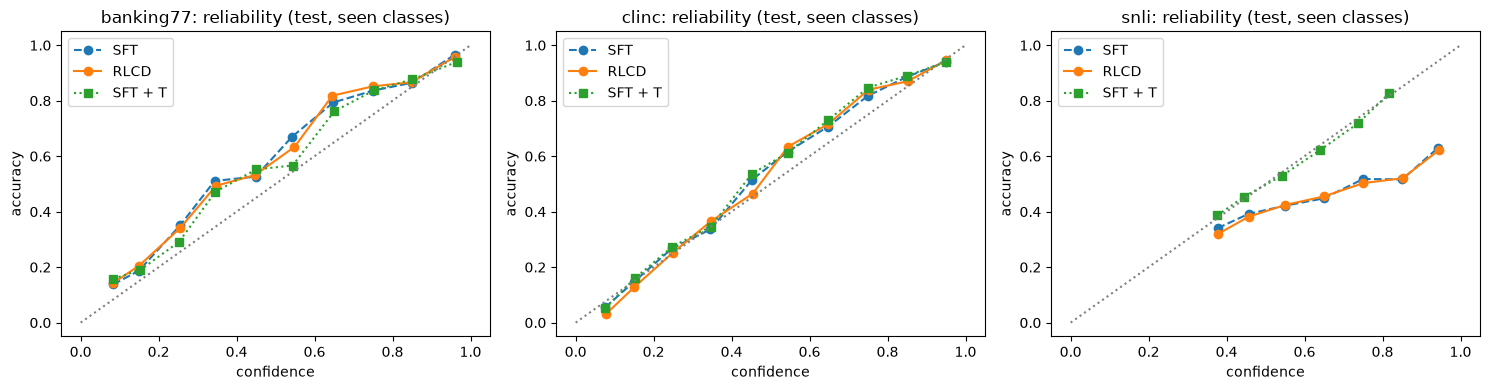

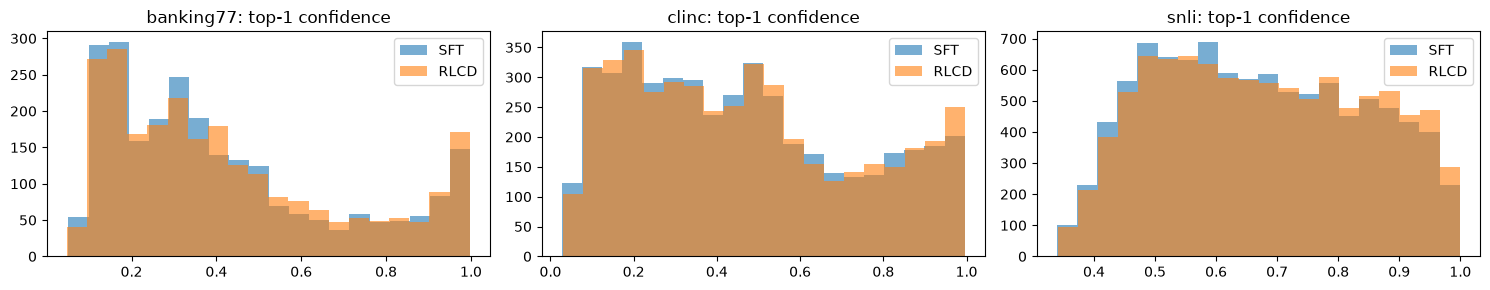

In [14]:
fig, ax = plt.subplots(1, len(tasks), figsize=(5 * len(tasks), 4), squeeze=False)
for j, t in enumerate(tasks):
    key = (t["name"], "test_seen", "T=1")
    for label, store, style in (("SFT", sft_store, "--"), ("RLCD", rlcd_results[0]["store"], "-")):
        xs, ys = rel_curve(*store[key])
        ax[0, j].plot(xs, ys, style, marker="o", label=label)
    xs, ys = rel_curve(*sft_store[(t["name"], "test_seen", "T fitted")])
    ax[0, j].plot(xs, ys, ":", marker="s", label="SFT + T")
    ax[0, j].plot([0, 1], [0, 1], color="gray", ls=":")
    ax[0, j].set_title(f"{t['name']}: reliability (test, seen classes)")
    ax[0, j].set_xlabel("confidence"); ax[0, j].set_ylabel("accuracy"); ax[0, j].legend()
plt.tight_layout(); plt.show()

# how much confidence changed: histogram of top-1 probability, SFT vs RLCD
fig, ax = plt.subplots(1, len(tasks), figsize=(5 * len(tasks), 3), squeeze=False)
for j, t in enumerate(tasks):
    key = (t["name"], "test_seen", "T=1")
    ax[0, j].hist(sft_store[key][0].max(1), bins=20, alpha=0.6, label="SFT")
    ax[0, j].hist(rlcd_results[0]["store"][key][0].max(1), bins=20, alpha=0.6, label="RLCD")
    ax[0, j].set_title(f"{t['name']}: top-1 confidence"); ax[0, j].legend()
plt.tight_layout(); plt.show()

### Does RLCD meet the README's "done when"?
For every task (seen classes): Brier and ECE below both the supervised model and its temperature-scaled version, and accuracy within
`ACC_TOL` of the supervised model. Mean over seeds. A FAIL is a real result, not an error.

In [15]:
print(f"{'task':11s}{'Brier vs SFT / SFT+T':>34s}{'ECE vs SFT / SFT+T':>34s}{'acc change':>12s}   verdict")
verdicts = {}
for t in tasks:
    n = t["name"]; k = lambda s: (n, "test_seen", s)
    b_r = mean_std(rlcd_outs, k("T=1"), "brier")[0]; b_s = sft_out[k("T=1")]["brier"]; b_st = sft_out[k("T fitted")]["brier"]
    e_r = mean_std(rlcd_outs, k("T=1"), "ece")[0];   e_s = sft_out[k("T=1")]["ece"];   e_st = sft_out[k("T fitted")]["ece"]
    a_r = mean_std(rlcd_outs, k("T=1"), "acc")[0];   a_s = sft_out[k("T=1")]["acc"]
    ok = b_r < min(b_s, b_st) and e_r < min(e_s, e_st) and a_r >= a_s - ACC_TOL
    verdicts[n] = bool(ok)
    print(f"{n:11s}{f'{b_r:.3f} vs {b_s:.3f} / {b_st:.3f}':>34s}{f'{e_r:.3f} vs {e_s:.3f} / {e_st:.3f}':>34s}{a_r - a_s:+12.3f}   {'PASS' if ok else 'FAIL'}")
print("\nOverall:", "all tasks pass" if all(verdicts.values()) else "not every task passes: see the table above")

task                     Brier vs SFT / SFT+T                ECE vs SFT / SFT+T  acc change   verdict
banking77              0.616 vs 0.626 / 0.620            0.083 vs 0.084 / 0.064      +0.011   FAIL
clinc                  0.644 vs 0.655 / 0.655            0.038 vs 0.035 / 0.040      +0.003   FAIL
snli                   0.704 vs 0.698 / 0.625            0.206 vs 0.196 / 0.013      +0.002   FAIL

Overall: not every task passes: see the table above


## Week 5: benchmark on unseen data
None of these datasets, and none of their label names, were used in training. The candidate labels are the dataset's class names
(for example `world`, `sports`, `business`, `science and technology`). The hypothesis from the README: a model that reads label words
should transfer to new topics, even if it is far from perfect.

Reading the numbers:
- **chance** and **majority class** show what no understanding scores.
- **SFT** and **RLCD** are zero-shot: no labelled example from the benchmark was used.
- **SFT + T (diagnostic)** fits one temperature on a few benchmark training rows. It is not a fair zero-shot number; it shows how much of the
  calibration error is only an over- or under-confident scale.
- **TF-IDF + logistic regression** is a supervised reference trained on `BENCH_FIT` labelled rows, to put the zero-shot numbers in context.
- **Label wording** is varied to see how sensitive the model is to how a class is named.